# Supplementary Figure — Optotagged-cell raincloud plots

Comparison of waveform, autocorrelogram, and firing-rate features across optotagged ChAT, GABA, and GLuT neurons.

In [1]:
from pathlib import Path
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ptitprince as pt
import seaborn as sns

## Setup

In [2]:
# Locate the input files whether Jupyter starts in the repository root
# or in the notebook directory.
project_candidates = (Path.cwd(), *Path.cwd().parents)
project_root = next(
    (
        path
        for path in project_candidates
        if (path / "data" / "tag" / "df_VEH.pkl").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Could not locate data/NAc_Putative/df_VEH.pkl from the current directory."
    )

data_path = project_root / "data" / "NAc_Putative"

# Fix category order so that colors remain stable across every panel.
group_order = ["GABA", "ChAT", "GLuT"]
group_palette = {
    "GABA": "#619A8F",
    "ChAT": "#B085D6",
    "GLuT": "#84155F",
}
palette = [group_palette[group] for group in group_order]

plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams.update({"font.size": 18})
mpl.rcParams["axes.spines.right"] = False
mpl.rcParams["axes.spines.top"] = False

## Select optotagged cells

In [3]:
feature_data = pd.read_pickle(data_path / "df_VEH.pkl")

# MATLAB-style unit indices in the three NumPy files are one-based. Convert
# them to the zero-based DataFrame index before assigning cell identities.
tagged_indices = {
    "ChAT": np.asarray(np.load(data_path / "CHAT.npy")[0], dtype=int) - 1,
    "GLuT": np.asarray(np.load(data_path / "Vglut.npy")[0], dtype=int) - 1,
    "GABA": np.asarray(np.load(data_path / "Vgat.npy")[0], dtype=int) - 1,
}

classification = pd.Series(pd.NA, index=feature_data.index, dtype="string")
for group, indices in tagged_indices.items():
    missing_indices = np.setdiff1d(indices, feature_data.index)
    if missing_indices.size:
        raise IndexError(f"{group} contains unknown row indices: {missing_indices.tolist()}")
    if classification.loc[indices].notna().any():
        raise ValueError(f"Overlapping optotagged indices detected while assigning {group}.")
    classification.loc[indices] = group

optotagged_cells = feature_data.loc[classification.notna()].copy()
optotagged_cells["Optotagged cell"] = classification.dropna()

for group in group_order:
    print(f"{group}: {(optotagged_cells['Optotagged cell'] == group).sum()} cells")

GABA: 16 cells
ChAT: 10 cells
GLuT: 40 cells


## A/B ratio distributions

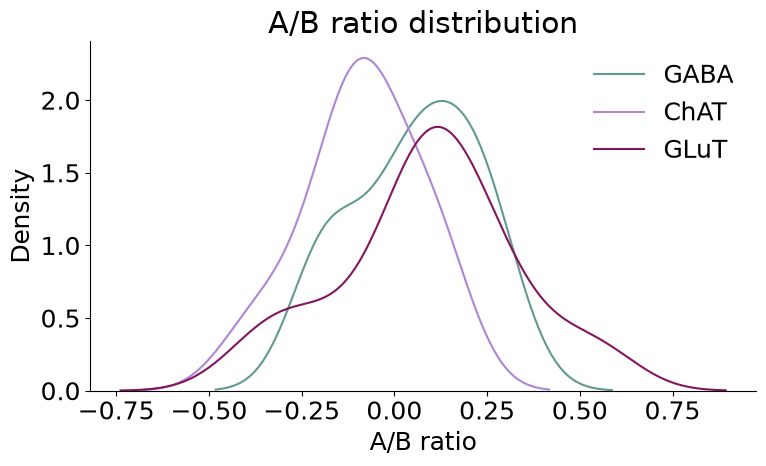

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
for group in group_order:
    group_values = optotagged_cells.loc[
        optotagged_cells["Optotagged cell"] == group,
        "ab_ratio",
    ]
    sns.kdeplot(
        group_values,
        label=group,
        color=group_palette[group],
        ax=ax,
    )
ax.set(xlabel="A/B ratio", ylabel="Density", title="A/B ratio distribution")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## A/B ratio raincloud plot

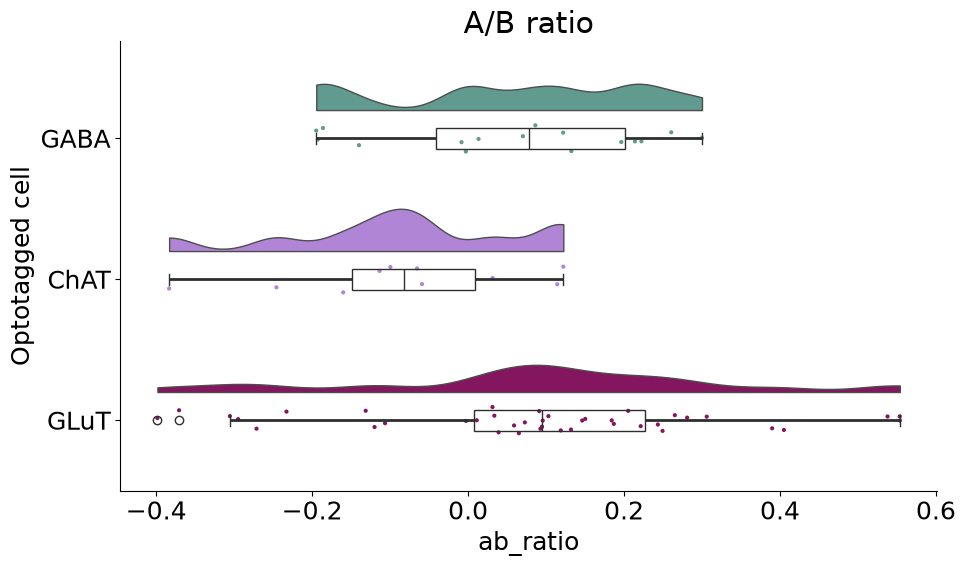

In [5]:
def plot_raincloud(feature, title=None):
    """Plot one feature using a fixed group order and color palette."""
    fig, ax = plt.subplots(figsize=(10, 6))
    # PtitPrince currently triggers a seaborn palette deprecation internally;
    # suppress only that known warning until the dependency is updated.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        pt.RainCloud(
            data=optotagged_cells,
            y=feature,
            x="Optotagged cell",
            order=group_order,
            palette=palette,
            width_viol=0.6,
            orient="h",
            ax=ax,
        )
    ax.set_title(title or feature)
    plt.tight_layout()
    plt.show()

plot_raincloud("ab_ratio", title="A/B ratio")

## Raincloud plots for all electrophysiological features

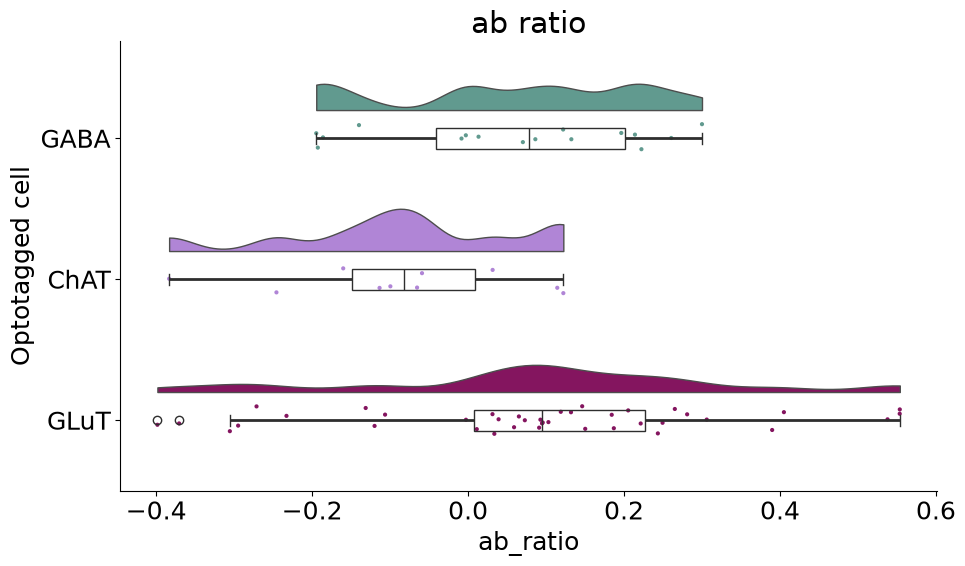

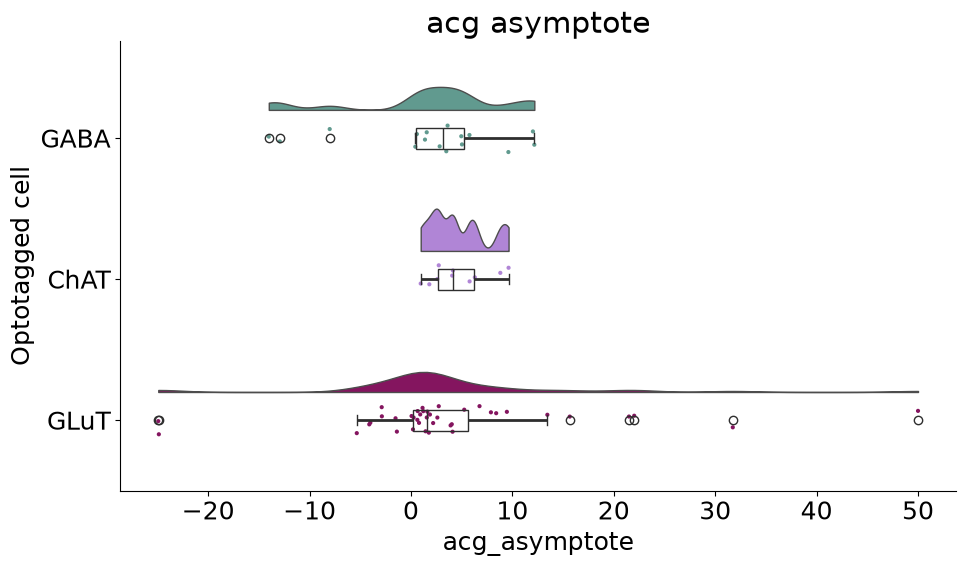

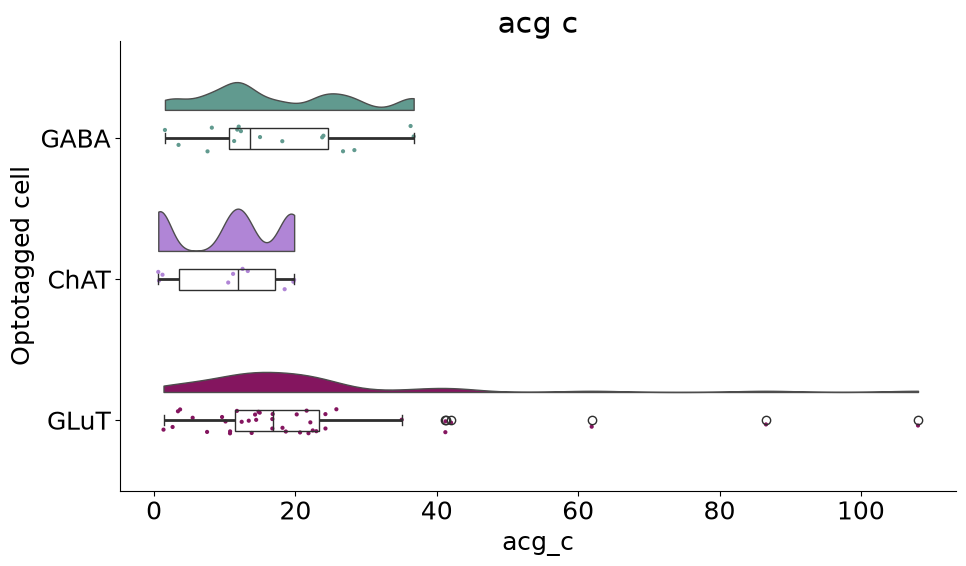

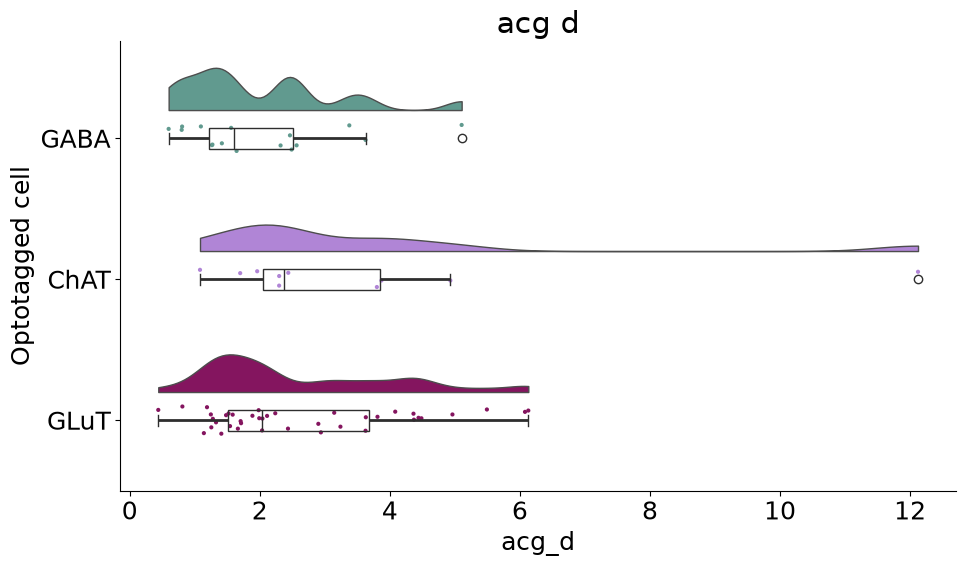

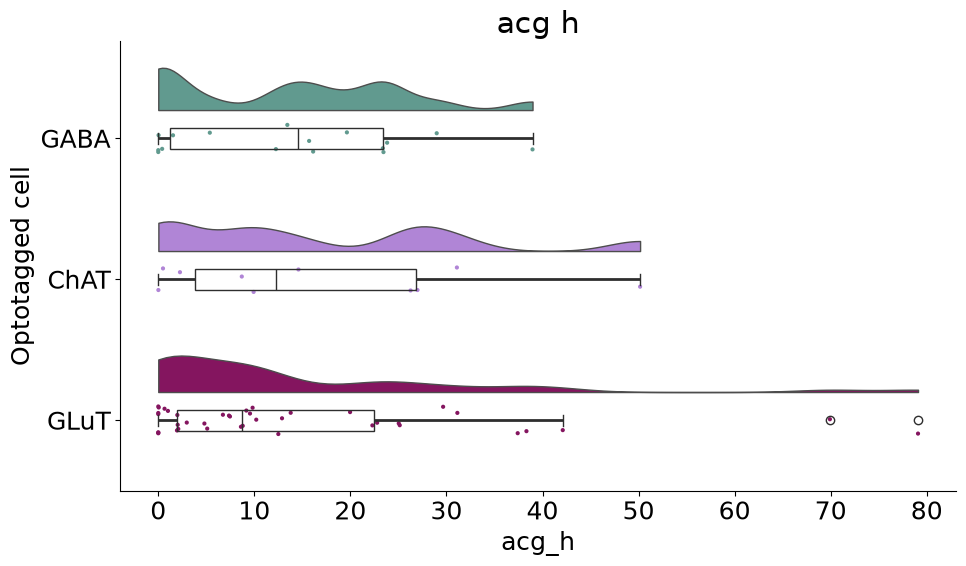

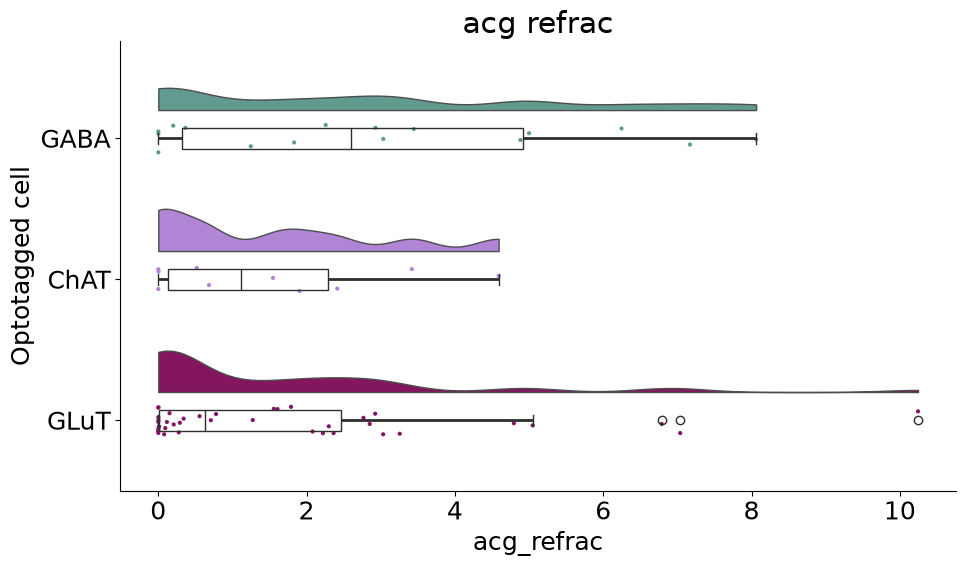

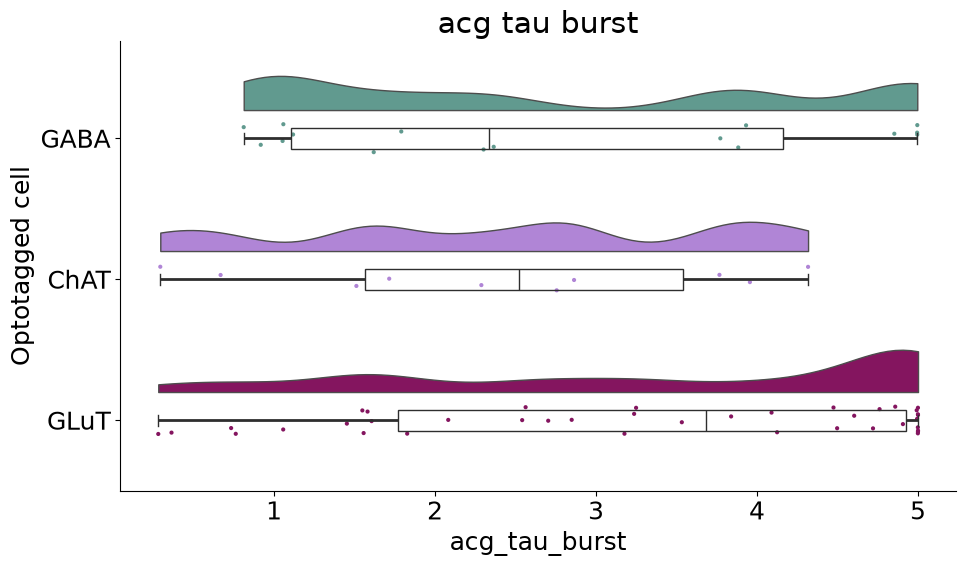

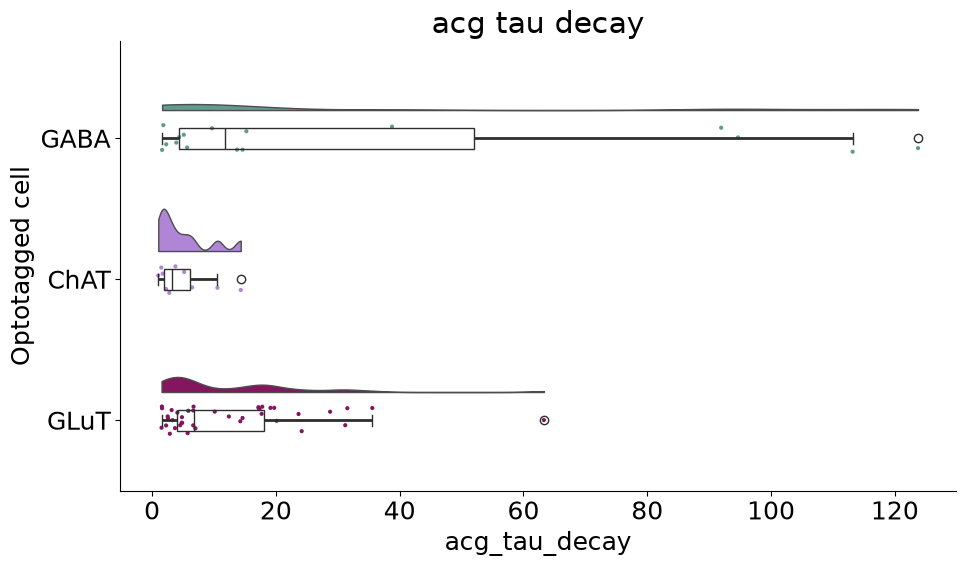

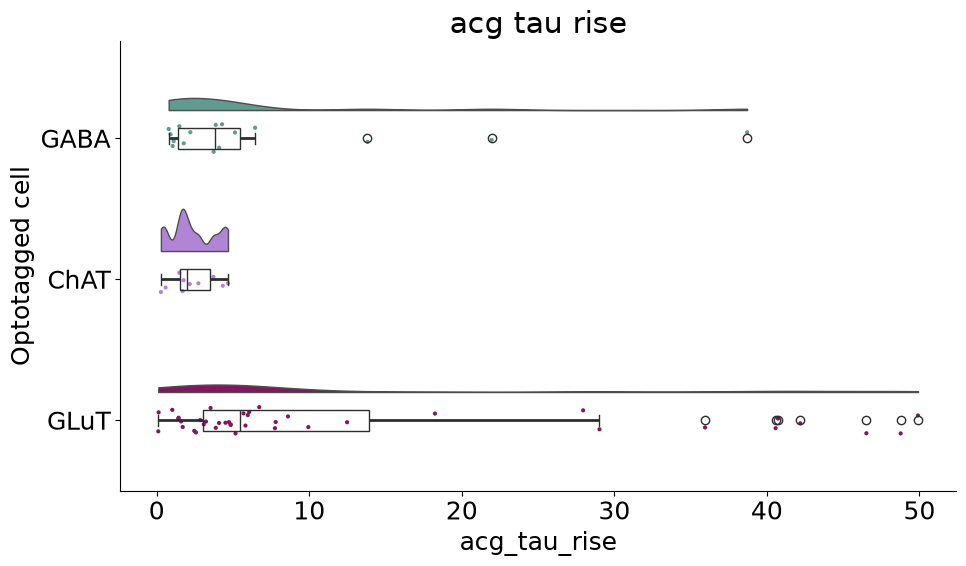

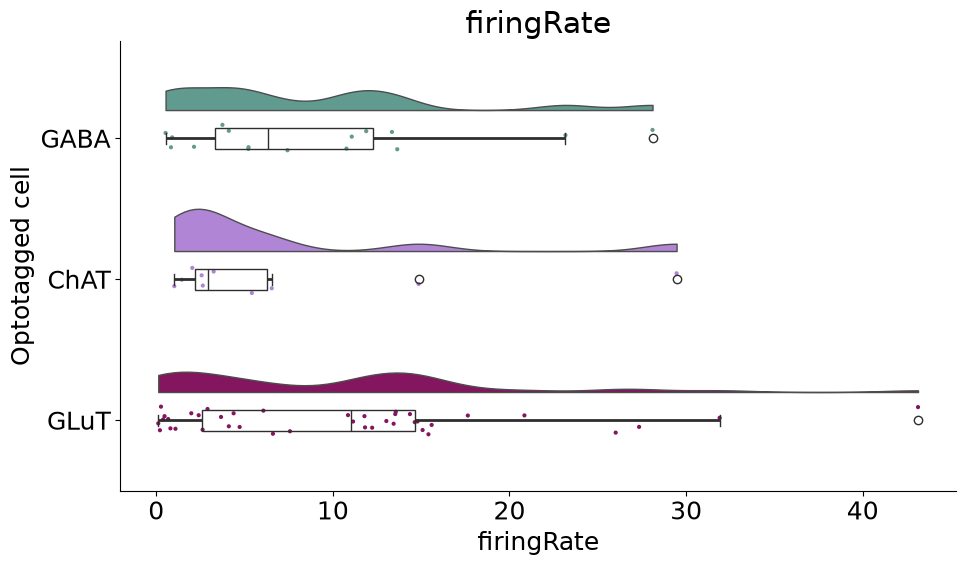

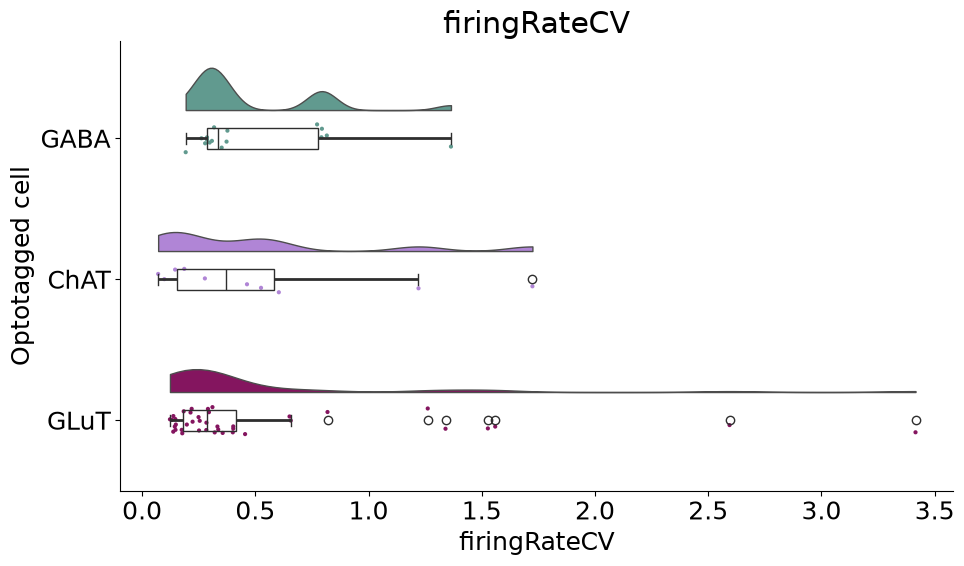

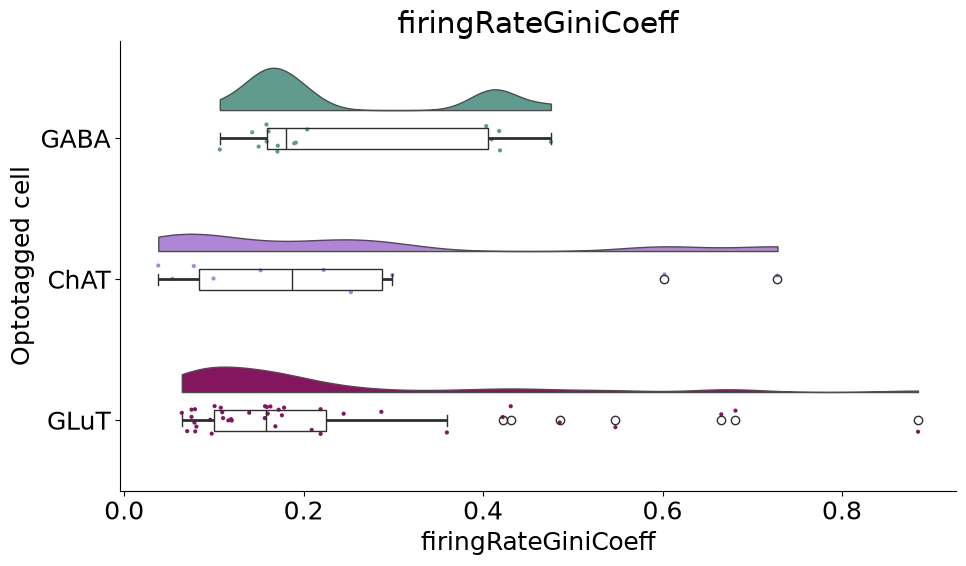

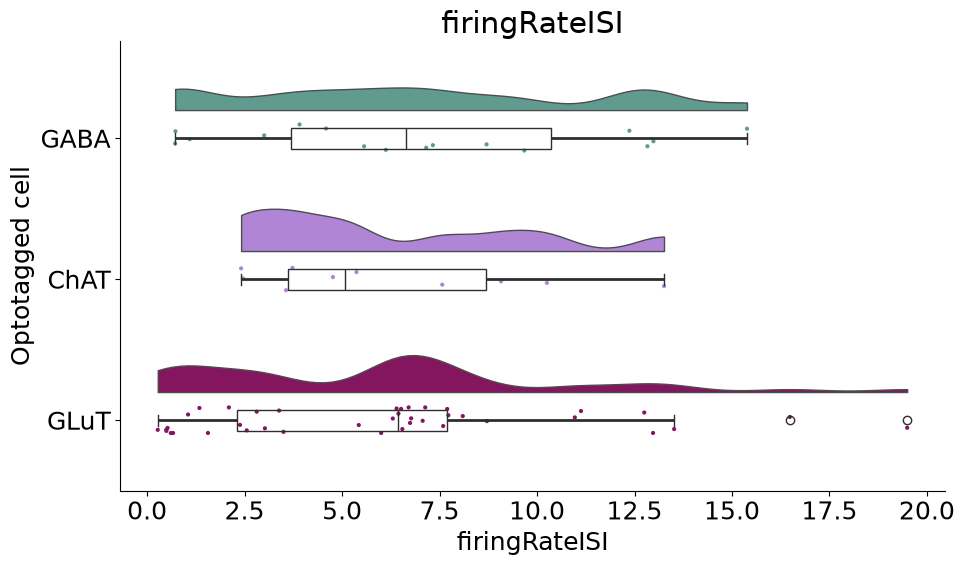

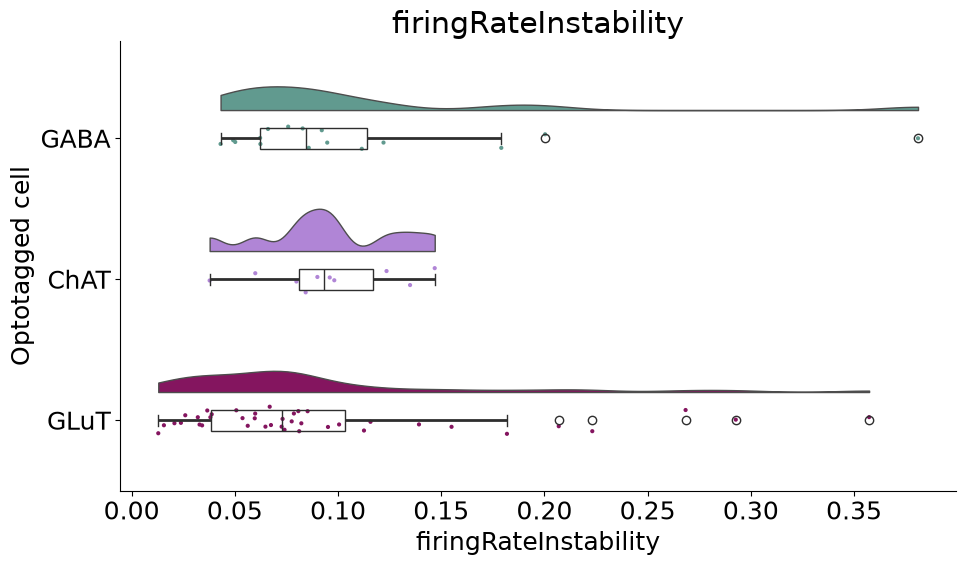

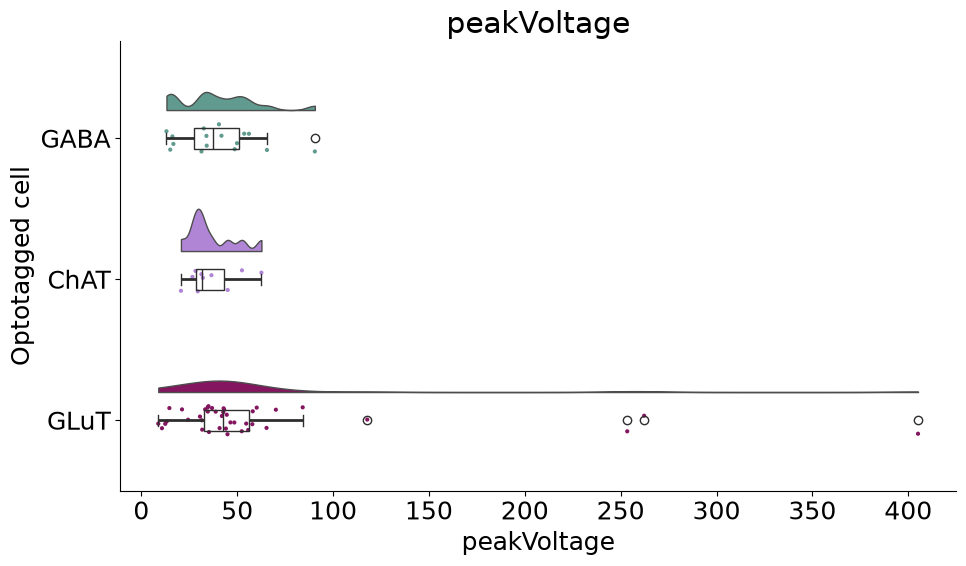

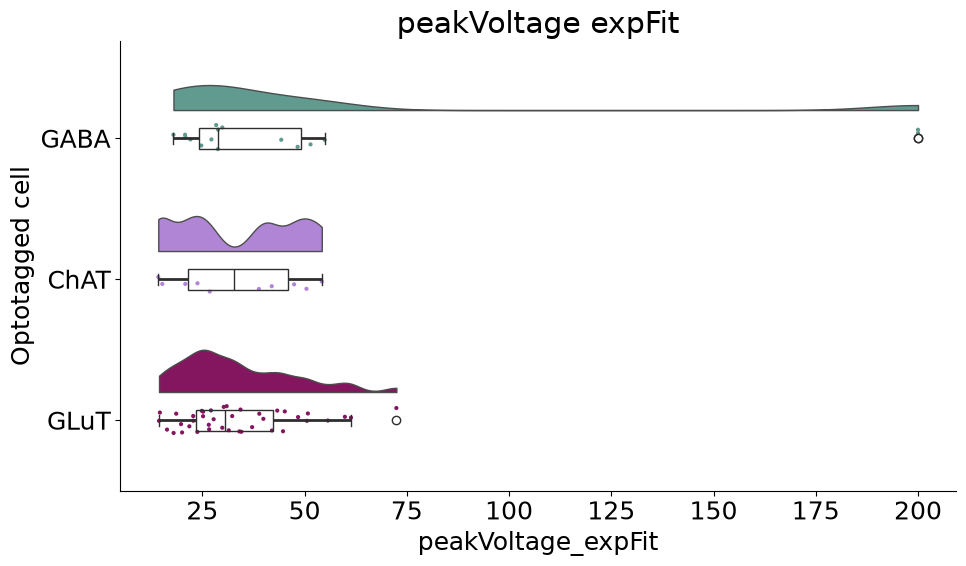

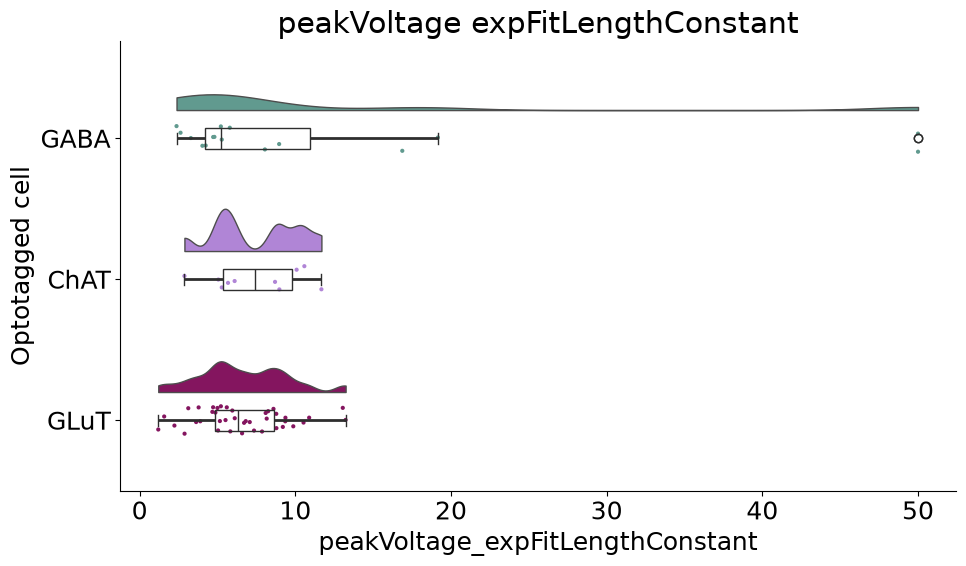

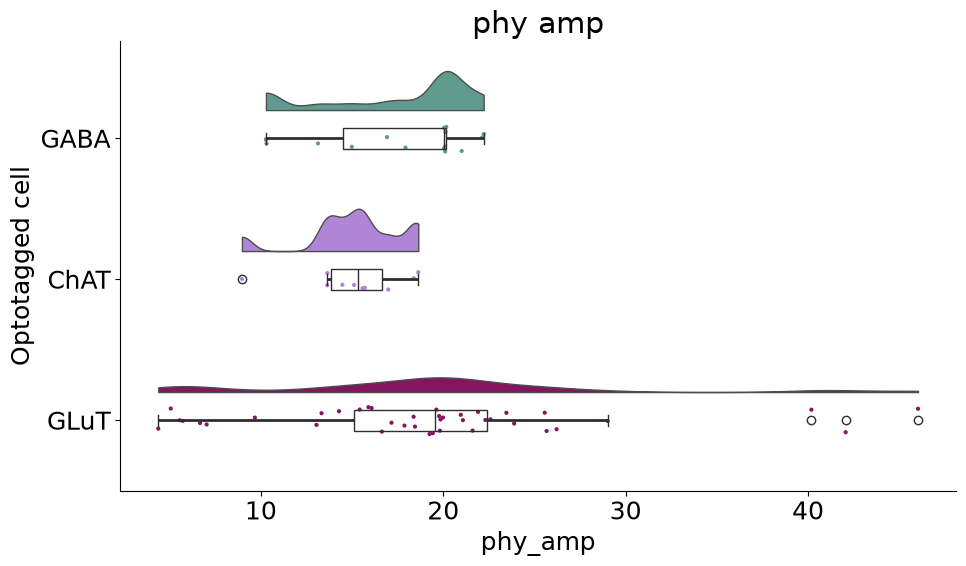

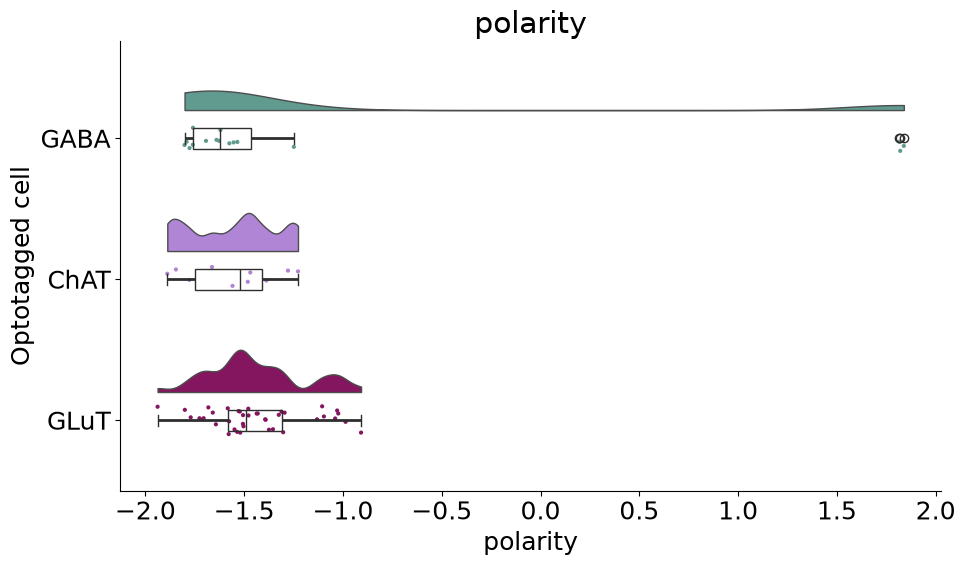

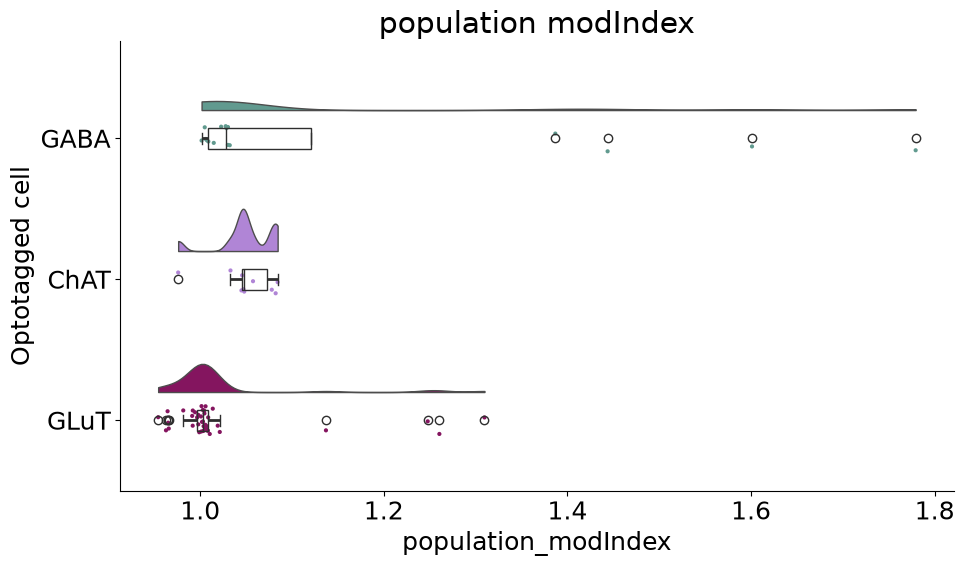

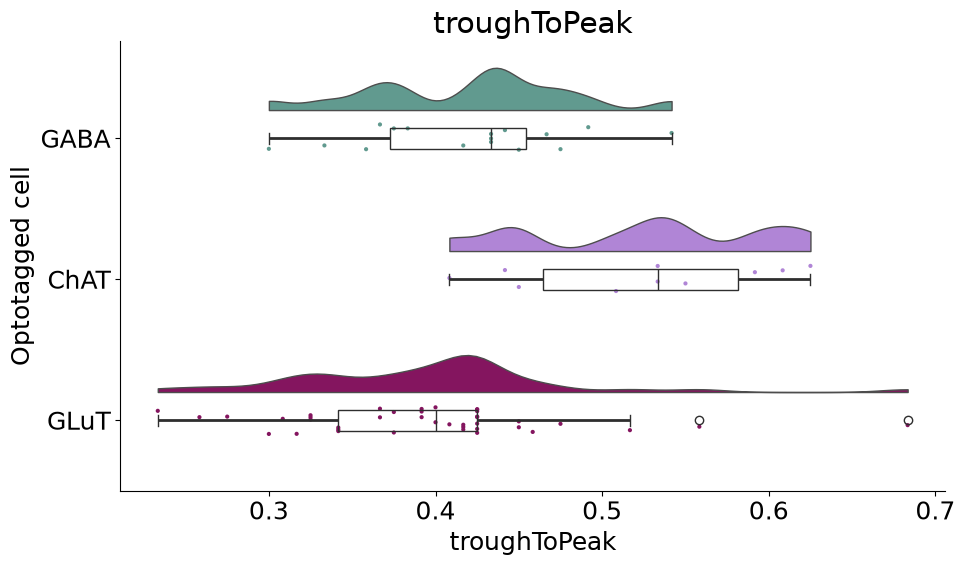

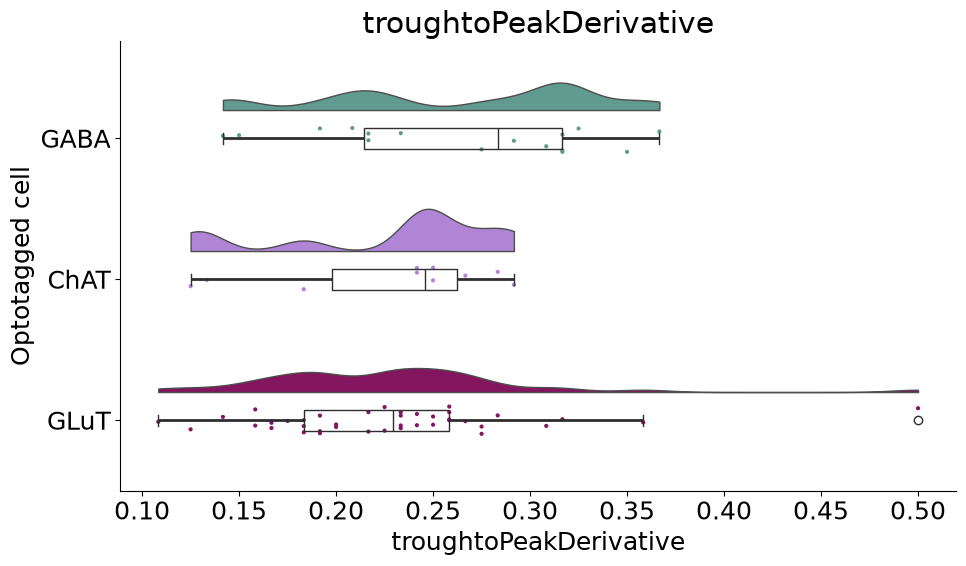

In [6]:
# The first 22 columns are the numerical electrophysiological features in
# the source table. Animal and unit identifiers are intentionally excluded.
feature_columns = feature_data.columns[:22].tolist()

for feature in feature_columns:
    plot_raincloud(feature, title=feature.replace("_", " "))